[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hbprosper/mlinphysics/blob/main/Labs/05.PINN/tutorial_PINN_SIR_Part2.ipynb)

# Physics Informed Neural Networks (PINN): SIR Model, Part 2
> For the Fall 2026 course: *Machine Learning in Physics*<br>
> Created: Oct. 18, 2026 Harrison B. Prosper<br>

## Introduction
Notebook `tutorial_PINN_SIR_Part1` implements a straightforward application of the PINN method [1, 2] to  the **S**usceptible, **I**nfectious, **R**ecovered (SIR) epidemiological model [3] defined by the coupled ordinary differential equations
\begin{align}
    \frac{dS}{dt} & = - R_0  S I,\quad
    \frac{dI}{dt}  = (R_0 S - 1)I ,\quad
    \frac{dR}{dt}  = I ,
\end{align}
where $t$ is the dimensionless time and $S$, $I$, and $R$ are the mean fractions of the population that are susceptible, infectious, or recovered, respectively. The quantity $R_0$ is the **reproduction number**. Notice that when $R_0 S > 1$ infections increase and decrease when $R_0 S < 1$.

In this notebook, we introduce a few improvements that markedly improve the accuracy of the results.

### References
  1. B. Moseley, see, for example, https://www.youtube.com/watch?v=IDIv92Z6Qvc; B. Moseley, Deep Learning in Scientific Computing (2023), ETH Zürich, Computational and Applied Mathematics Laboratory (CAMLab).
  2. S. Cuomo et al., *Scientific Machine Learning through Physics-Informed Neural Networks: Where we are and What's next*, https://doi.org/10.48550/arXiv.2201.05624.
  3. LibreTexts: [SIR Model](https://math.libretexts.org/Bookshelves/Applied_Mathematics/Mathematical_Biology_(Chasnov)/04%3A_Infectious_Disease_Modeling/4.03%3A_The_SIR_Epidemic_Disease_Model)
  4. D. Mortari, The Theory of Connections: Connecting Points, Mathematics, vol. 5, no. 57, 2017.
  5. W. O. Kermack and A. G. McKendrick, *A contribution to the mathematical theory of epidemics*, Proc. R. Soc. Lond. A **115**, 700 (1927), https://doi.org/10.1098/rspa.1927.0118.

## Running on Google Colab
If on Google Colab (https://colab.research.google.com), execute cell below.

In [1]:
try:
    import google.colab
    
    REPO = 'hbprosper/mlinphysics'
    
    url = f"https://raw.githubusercontent.com/{REPO}/refs/heads/main"
    !wget -q {url}/clone2colab.ipynb -O clone2colab.ipynb
    %run clone2colab.ipynb
    
    IN_COLAB = True

except ImportError:
    
    IN_COLAB = False

In [2]:
# standard system modules
import os, sys, copy

# standard module for tabular data
import pandas as pd

# standard module for array manipulation
import numpy as np

# standard module for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

# standard research-level machine learning toolkit from Meta (FKA: FaceBook)
import torch
import torch.nn as nn
import torch.nn.init as init

from scipy.integrate import solve_ivp

# to reload modules
import importlib

# ML in physics module
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon

# module for shell utilities
import shutil

plt.rcParams.update({
      "text.usetex": shutil.which('latex') is not None,
      "font.family": "sans-serif",
      "font.size": 12
})

In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tComputational device: {str(DEVICE):4s}\n')


	Computational device: cpu 



## Solution using `solve_ivp`

```python
solve_ivp(fun, t_span, y0, method='RK45', t_eval=None, 
    dense_output=False, events=None, vectorized=False, 
    args=None, **options)
```

\begin{align}
    \frac{dS}{dt} & = - R_0  S I,\quad
    \frac{dI}{dt}  = + R_0 S I - I ,\quad
    \frac{dR}{dt}  = I ,
\end{align}

In [4]:
class RK45Solution:
    
    def __init__(self, S0, I0, R_0):

        # initial conditions
        self.S0 = S0
        self.I0 = I0
        self.R0 = 1 - S0 - I0
        
        # reproduction number
        self.R_0 = R_0

    def fun__(self, t, u):
        S, I, R =  u
        return [-self.R_0 * S * I, self.R_0 * S * I - I, I]

    def __call__(self, t, rtol=1e-4, atol=1e-7):

        # initial conditions
        y0 = self.S0, self.I0, self.R0

        # domain
        t_span  = [t[0], t[-1]]
        
        self.results = solve_ivp(
            self.fun__, t_span, y0, method='RK45', 
            t_eval=t, rtol=rtol, atol=atol)
        
        return self.results.y[0], self.results.y[1], self.results.y[2]

    def plot(self, ymin=0, ymax=1, 
             filename='results.png', width=6, ftsize=14):
        S, I, R = self.results.y
        t = self.results.t
        xmin, xmax = t[0], t[-1]

        fgsize = (width, width*9/16)
        # create an empty figure
        fig = plt.figure(figsize=fgsize)
        
        ax  = fig.add_subplot(1, 1, 1)
            
        ax.set_xlim(xmin, xmax)
        ax.set_xlabel(r'$t$', fontsize=ftsize)
        
        ax.set_ylabel(r'$S$, $I$, $R$', fontsize=ftsize)
        ax.set_ylim(ymin, ymax)
        
        ax.plot(
            t, S, color='blue', linestyle='solid', linewidth=1.0, label='S')
        
        ax.plot(
            t, I, color='red',  linestyle='solid', linewidth=1.0, label='I')
        
        ax.plot(
            t, R, color='green',linestyle='solid', linewidth=1.0, label='R')
        
        ax.legend()
        
        ax.grid()
        
        fig.tight_layout()
        plt.savefig(filename)

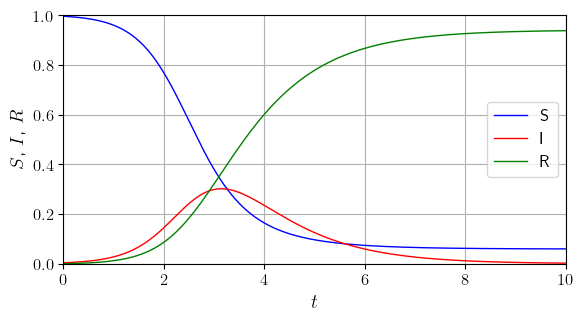

In [5]:
N  = 766
I0 = 3 / N
S0 = 1 - I0
R0 = 0

R_0= 3.0  # reproduction number

tmin, tmax = 0, 10
soln = RK45Solution(S0, I0, R_0)
t = np.linspace(tmin, tmax, 201)

S, I, R = soln(t)

soln.plot()

## Configuration

### Choice of domain
The PINN is a single network that solves the SIR equations for a *family* of problems, labeled by $p = (I_0, R_0)$. Two choices about the domain matter more than one might expect.

1. **Time range $t \in [0, 12]$**.

2. **$I_0 \in [0.001, 0.1]$**. The case $I_0 = 0$ is excluded: it is the trivial, disease-free solution, and $y_0 = \ln I_0$ (see below) would be undefined.

**Sampling of $I_0$.** The switch `LOG_SAMPLING` in the cell below selects how $I_0 \in [0.001, 0.1]$ is sampled. With `LOG_SAMPLING = False`, $I_0$ is sampled uniformly, which puts about 90% of the points at $I_0 > 0.01$ and only about 10% in $[0.001, 0.01]$, where the dynamics are hardest to learn. With `LOG_SAMPLING = True`, $\log_{10} I_0$ is sampled uniformly, which puts equal numbers of points in $[0.001, 0.01]$ and $[0.01, 0.1]$. The validation and test points are sampled in the same way, so the switch also changes which values of $I_0$ the accuracy summary at the end emphasizes. To compare Parts 1 and 2 fairly, use the same setting in both.

**L-BFGS.** The switch `config('lbfgs', ...)` turns on an optional second training stage with the L-BFGS optimizer (see *Polish with L-BFGS* below). It is off by default so that Parts 1 and 2 are trained identically, with Adam only, and differ only in how the SIR equations are formulated.

**Batch size and GPUs.** Our network is small (three hidden layers of 64 nodes), so each operation in a training step, a $256 \times 64$ matrix multiplication say, involves very little arithmetic. On a GPU, the time per step is then dominated by the fixed cost of launching each operation, not by the arithmetic itself, and a GPU is no faster than a CPU. A GPU pays off only when each operation has enough work to keep its thousands of cores busy. We therefore use a large batch, $2^{12} = 4096$ points. On a GPU, the time per step hardly changes compared with a batch of 256 points, while each step uses 16 times as many points. With less noisy gradients, we can also use a larger learning rate and fewer iterations.

In [6]:
dataset_size_exponent = 17
dataset_size = 2**dataset_size_exponent  # Sobol sample size
test_size    = 2**13                     # test sample size
val_size     = 2**11                     # validation sample size
batch_size   = 2**12                     # large batches keep a GPU busy (see note above)

# domain of PINN solution
# -----------------------------------------
LOG_SAMPLING = False   # True:  sample I0 uniformly in log10(I0)
                       # False: sample I0 uniformly in I0
tmax = 12.0
I0_min, I0_max = 1e-3, 1e-1
R0_min, R0_max = 0.5, 5.0

# sampling bounds for (t, I0, R_0); if LOG_SAMPLING, the second
# coordinate is log10(I0), which is converted to I0 after sampling
if LOG_SAMPLING:
    lower_bounds = [0.0,  np.log10(I0_min), R0_min]
    upper_bounds = [tmax, np.log10(I0_max), R0_max]
else:
    lower_bounds = [0.0,  I0_min, R0_min]
    upper_bounds = [tmax, I0_max, R0_max]

# the network inputs are (t, log10(I0), R_0), mapped to [-1, 1]
# using these bounds (whichever way I0 is sampled)
input_lo = [0.0,  np.log10(I0_min), R0_min]
input_hi = [tmax, np.log10(I0_max), R0_max]

# name of model
name = 'sir'
dirname = 'pinn2'

# create new configuration
config = mlp.Config(name, dirname=dirname)

# training configuration
# -----------------------------------------
train_size = dataset_size - val_size

config('batch_size', batch_size)
config('train_size', train_size)           # set training sample size
config('test_size',  test_size)            # set test sample size
config('val_size',   val_size)             # set validation sample size

config('monitor_step',  100)  # set monitor training every "n" iterations
config('delete', True)        # delete losses file before training, if True
config('frac', 0.015)         # save model if average loss decreases by more
                              # than frac percent

# optimizer / scheduler configuration
# -----------------------------------------
# a step comprises a given number of iterations
config('n_iters_per_step', 10_000)
config('n_steps', 8)          # number of training steps
config('n_iterations', config('n_steps') * config('n_iters_per_step'))

config('base_lr', 1e-3)       # initial learning rate
config('gamma', 0.80)         # learning rate scale factor

# L-BFGS polishing stage (see "Polish with L-BFGS")
# -----------------------------------------
config('lbfgs', False)        # True: polish the Adam result with L-BFGS
config('lbfgs_outer', 20)     # number of outer rounds (new batch each round)
config('lbfgs_points', 8192)  # (fixed) batch size within a round
config('lbfgs_max_iter', 100) # maximum L-BFGS iterations per round

print(f'\nSave configuration to file {config('file/config')}\n')
config('log_sampling', LOG_SAMPLING)
config.save()

print(config)


Save configuration to file runs/pinn2/sir_config.yaml

name: sir
file:
  losses: runs/pinn2/sir_losses.csv
  params: runs/pinn2/sir_params.pth
  init_params: runs/pinn2/sir_init_params.pth
  plots: runs/pinn2/sir_plots.png
  config: runs/pinn2/sir_config.yaml
batch_size: 4096
train_size: 129024
test_size: 8192
val_size: 2048
monitor_step: 100
delete: true
frac: 0.015
n_iters_per_step: 10000
n_steps: 8
n_iterations: 80000
base_lr: 0.001
gamma: 0.8
lbfgs: false
lbfgs_outer: 20
lbfgs_points: 8192
lbfgs_max_iter: 100
log_sampling: false



## Train, validation, and test sets
There is some confusion in terminology regarding validation and test samples (or sets). We shall adhere to the defintions given here https://machinelearningmastery.com/difference-test-validation-datasets/):
   
  * __Training Dataset__: The sample of data used to fit the model.
  * __Validation Dataset__: The sample of data used to decide 1) whether the fit is reasonable (e.g., the model has not been overfitted), 2) decide which of several models is the best and 3) tune model hyperparameters.
  * __Test Dataset__: The sample of data used to provide an unbiased evaluation of the fitted model.

The validation set will be some small fraction of the training set and will be used to decide when to stop the training.

## Generate raw data
Generate a quasi-random set of points, $p$, in $S_t \otimes S \subset \mathbb{R}^3$, where the set $S_t = [0, 12]$ with $t \in S_t$. Quasi-random sampling disributes points more evenly than uniform random sampling by reducing the degree if random clumping that characterizes random sampling.

In [7]:
sobol_sample = dat.SobolSample(lower_bounds, upper_bounds,
                               num_points_exp=dataset_size_exponent)
print()

uniform_sample = dat.UniformSample(lower_bounds, upper_bounds,
                                   num_points=test_size)

if LOG_SAMPLING:
    # column 1 was sampled uniformly in log10(I0); convert it to I0
    sobol_sample[:, 1]   = 10**sobol_sample[:, 1]
    uniform_sample[:, 1] = 10**uniform_sample[:, 1]

print(f'I0 range: [{sobol_sample[:, 1].min():.2e}, {sobol_sample[:, 1].max():.2e}]')
print(f'fraction of points with I0 < 0.01: {(sobol_sample[:, 1] < 0.01).mean():.2f}')

sobol_sample.shape, uniform_sample.shape

SobolSample
  131072 Sobol points created in unit 3-cube.

UniformSample
  8192 uniformly sampled points created in unit 3-cube.
I0 range: [1.00e-03, 1.00e-01]
fraction of points with I0 < 0.01: 0.09


((131072, 3), (8192, 3))

## Package raw data into `Dataset`s

In [8]:
importlib.reload(dat)

train_size = config('train_size')
val_size   = config('val_size')
test_size  = config('test_size')

# training dataset (this defines the empirical risk to be minimized)
print('training data')
train_data = dat.Dataset(sobol_sample,
                         start=0,
                         end=train_size,
                         # split at: y = x[:, split_col:], x = x[:, :split_col]
                         split_col=1,  
                         requires_grad=True)

# a random subset of the training data to check for overtraining
# by comparing with the empirical risk from the validation set
print('training data for validation')
train_data_val = dat.Dataset(sobol_sample,
                             start=0,
                             end=train_size,
                             split_col=1,
                             requires_grad=True,
                             random_sample_size=val_size)


# validation dataset (for monitoring training)
print('validation data')
val_data = dat.Dataset(uniform_sample,
                       start=0,
                       end=val_size, 
                       split_col=1,
                       requires_grad=True)

# test dataset
print('test data')
test_data= dat.Dataset(uniform_sample,
                       start=val_size,
                       end=val_size + test_size,
                       split_col=1,
                       requires_grad=True)

training data
Dataset
  shape of x: torch.Size([129024, 1])
  shape of y: torch.Size([129024, 2])

training data for validation
Dataset
  shape of x: torch.Size([2048, 1])
  shape of y: torch.Size([2048, 2])

validation data
Dataset
  shape of x: torch.Size([2048, 1])
  shape of y: torch.Size([2048, 2])

test data
Dataset
  shape of x: torch.Size([6144, 1])
  shape of y: torch.Size([6144, 2])



## Define `DataLoader`s

In [9]:
print('train data loader')
train_loader = dat.DataLoader(train_data,
                              batch_size=config('batch_size'),
                              num_iterations=config('n_iterations'))

print('train data loader for validation')
train_loader_val = dat.DataLoader(train_data_val,
                                  batch_size=len(train_data_val))

print('validation data loader')
val_loader  = dat.DataLoader(val_data,
                             batch_size=len(val_data))

print('test data loader')
test_loader = dat.DataLoader(test_data,
                             batch_size=len(test_data))

train data loader
DataLoader
  Number of iterations has been specified
  maxiter:           80000
  batch_size:         4096
  shuffle_step:         31

train data loader for validation
DataLoader
  maxiter:               1
  batch_size:         2048
  shuffle_step:          1

validation data loader
DataLoader
  maxiter:               1
  batch_size:         2048
  shuffle_step:          1

test data loader
DataLoader
  maxiter:               1
  batch_size:         6144
  shuffle_step:          1



## Define Solution *ansatz*

### Why the obvious PINN fails for small $I_0$ in the SIR model
The obvious approach is to model $(S, I, R)$ directly and minimize the mean square of the residuals
\begin{align}
    F_1 = \frac{dS}{dt} + R_0 S I, \quad F_2 = \frac{dI}{dt} - (R_0 S - 1) I,
\end{align}
which is the approach of `tutorial_PINN_SIR_Part1`.
However, this approach does poorly for small values of $I_0$. To see why, look at the residuals while $I$ is still small. Both terms in $F_2$ are proportional to $I$ or to its derivative. In $F_1$, the only term that involves $I$, namely $R_0 S I$, is also small, so $F_1$ merely requires $dS/dt \approx 0$, which says nothing about how fast $I$ grows. Suppose the network gets the early growth rate of the infection wrong: instead of $dI/dt = (R_0 S - 1) I$, its $I$ grows as $dI/dt = (R_0 S - 1 + \delta) I$. The residual is then $F_2 = \delta I$. For $I \approx 0.001$ and $\delta = 0.5$, that is, a 50% error in a growth rate of order 1, $F_2 \approx 5 \times 10^{-4}$, which contributes only about $10^{-7}$ to the average loss. The loss barely notices the error.

But an error in a growth rate compounds exponentially. By the time $I$ is large enough for the loss to notice, the epidemic is already shifted in time. That is what we see in `tutorial_PINN_SIR_Part1`: for small $I_0$, the PINN produces curves of the right shape, but the epidemic happens at the wrong time. The extreme case is the **disease-free state** $I = 0$, which satisfies the SIR equations exactly: the closer $I$ is to zero, the less the loss cares what $I$ does.

In short, the loss is least sensitive to precisely the phase of the dynamics that determines *when* the epidemic happens: the early, exponential growth of a small number of infections, which occurs whenever $R_0 S > 1$. 

### One remedy: work with logarithms
Dividing the first two SIR equations by $S$ and $I$, respectively, and defining $x = \ln S$ and $y = \ln I$ yields
\begin{align}
    \frac{dx}{dt} = - R_0 \exp(y), \quad \frac{d y}{dt} = R_0 \exp(x) - 1 .
\end{align}
The right-hand sides are now of order 1 no matter how small $I$ is: what is constrained is the *growth rate* of $I$, and a network that suppresses the epidemic now pays a price of order 1. We therefore let the neural network model $x$ and $y$ directly, using the Theory of Connections (ToC) ansatz [4]
\begin{align}
    x(t, p) & = x_0 + g_\omega(t, p) - g_\omega(0, p), \\
    y(t, p) & = y_0 + h_\omega(t, p) - h_\omega(0, p),
\end{align}
where $x_0 = \ln S_0 = \ln(1 - I_0)$, $y_0 = \ln I_0$, and $(g_\omega, h_\omega)$ are the two outputs of a neural network with parameters $\omega$ and inputs $t$ and $p = (I_0, R_0)$. Everything else follows from $x$ and $y$: $S = \exp(x)$, $I = \exp(y)$, and $R = 1 - S - I$. This ansatz has four useful properties:

  1. The initial conditions are satisfied *exactly*: at $t = 0$, the last two terms in each line cancel, so $S = S_0$, $I = I_0$, and $R = 0$ whatever the values of the parameters $\omega$.
  2. The initial slopes are not constrained: $dx/dt|_{t=0} = \partial g_\omega / \partial t|_{t=0}$.
  3. $S$ and $I$ are positive by construction.
  4. $S + I + R = 1$ holds exactly. Consequently, the third SIR equation need not be part of the loss: $dR/dt = -dS/dt - dI/dt = R_0 S I - R_0 S I + I = I$ automatically, once the first two are satisfied.

The network inputs are $t$, $\log_{10} I_0$, and $R_0$, each mapped linearly to $[-1, 1]$ so that they are of order 1.

The `forward` method of the `Solution` class returns $(x, y)$, which is all the objective function needs. The method `sir` returns $(S, I, R)$, which we need for plotting and for comparisons with the numerical solution.

In [10]:
class Solution(mlp.Model):

    def __init__(self, net, input_lo, input_hi):

        # remember to initialize base (that is, parent) class
        super().__init__()

        # cache neural network
        self.g = net

        # The network inputs (t, log10(I0), R_0) are mapped linearly to
        # [-1, 1] so that they are of O(1). Use register_buffer to tell
        # PyTorch to save the bounds along with the network weights, but
        # not to optimize them!
        self.register_buffer(
            'lo', torch.tensor(input_lo, dtype=torch.float32).unsqueeze(dim=0))
        self.register_buffer(
            'hi', torch.tensor(input_hi, dtype=torch.float32).unsqueeze(dim=0))

    def scale(self, t, p):
        # map (t, log10(I0), R_0) to [-1, 1]
        z = torch.cat([t, torch.log10(p[:, 0:1]), p[:, 1:2]], dim=1)
        z = 2 * (z - self.lo) / (self.hi - self.lo) - 1
        return z[:, :1], z[:, 1:]

    def forward(self, t, p):
        """
        ToC ansatz:
            x = x0 + g(t, p) - g(0, p),  y = y0 + h(t, p) - h(0, p)
        where x = ln S, y = ln I, x0 = ln(1 - I0), y0 = ln I0.

        Assumes:
        - t: dimensionless time of shape (batch_size, 1)
        - p: (I0, R_0) of shape (batch_size, 2)

        Returns:
        - (x, y) of shape (batch_size, 2)
        """
        I0 = p[:, 0:1]
        xy0 = torch.log(torch.cat([1 - I0, I0], dim=1))    # (x0, y0)

        ts, ps = self.scale(t, p)
        t0, _  = self.scale(torch.zeros_like(t), p)

        gh  = self.g(ts, ps)    # (g, h) at t
        gh0 = self.g(t0, ps)    # (g, h) at t = 0

        return xy0 + gh - gh0   # (x, y)

    def sir(self, t, p):
        """
        Return (S, I, R) of shape (batch_size, 3).
        """
        SI = torch.exp(self(t, p))
        R  = 1 - SI.sum(dim=1, keepdim=True)  # S + I + R = 1 exactly
        return torch.cat([SI, R], dim=1)

## Objective function
In terms of $x = \ln S$ and $y = \ln I$, the residuals are
\begin{align}
    G_1 = \frac{dx}{dt} + R_0 \exp(y), \quad G_2 = \frac{dy}{dt} - \left(R_0 \exp(x) - 1\right),
\end{align}
where the derivatives are computed with `autograd`. The average loss is the mean of $(G_1^2 + G_2^2)/2$.

In [11]:
class Objective(mlp.Model):
    """
    Physics-based average loss for the PINN.

    Computes the residuals of the SIR equations in terms of
    x = ln S and y = ln I,
        dx/dt = -R_0 exp(y),   dy/dt = R_0 exp(x) - 1,
    and returns their mean square.
    """
    def __init__(self, solution):
        super().__init__()
        self.solution = solution

    def eval(self):
        self.solution.eval()
        return self

    def train(self, mode=True):
        self.solution.train(mode)
        return self

    def forward(self, t, p):
        # Assumes inputs come with shape (batch_size, D)
        xy = self.solution(t, p)
        x  = xy[:, 0]
        y  = xy[:, 1]

        # dx/dt
        dxdt = torch.autograd.grad(
            x, t,
            grad_outputs=torch.ones_like(x),
            create_graph=True
        )[0][:, 0]

        # dy/dt
        dydt = torch.autograd.grad(
            y, t,
            grad_outputs=torch.ones_like(y),
            create_graph=True
        )[0][:, 0]

        R_0 = p[:, 1] # reproduction number

        # residuals
        G1 = dxdt + R_0 * torch.exp(y)
        G2 = dydt - (R_0 * torch.exp(x) - 1)

        return torch.mean(G1**2 + G2**2) / 2

## Instantiate training objects
  1. gnet: the network with outputs $(g_\omega, h_\omega)$; no output activation, since they may be of either sign
  2. solution: the ToC ansatz for $(x, y) = (\ln S, \ln I)$
  3. objective
  4. optimizer
  5. scheduler
  6. monitor

In [12]:
gnet      = mlp.FCNN(
    n_inputs=3, n_hidden=3, n_width=64, n_outputs=2).to(DEVICE)

#gnet.apply(mlp.initialize_parameters) # initialize parameters

solution  = Solution(gnet, input_lo, input_hi).to(DEVICE)

objective = Objective(solution).to(DEVICE)

optimizer = torch.optim.Adam(solution.parameters(), lr=config('base_lr'))

# instantiate learning rate step scheduler
scheduler = mlp.LRStepScheduler(
    optimizer,  
    n_steps=config('n_steps'), 
    n_iters_per_step=config('n_iters_per_step'), 
    base_lr=config('base_lr'), 
    gamma=config('gamma')
)

# instantiate object that saves average losses to
# a csv file for realtime monitoring
monitor = mon.Monitor(
    config('n_iterations'),
    config('file/losses'),
    monitorstep=config('monitor_step'),
    newlossfile=True,
    frac=config('frac'),
    model=solution,
    paramsfile=config('file/params'))

print(solution)

print(f'Number of parameters: {mlp.number_of_parameters(solution)}')

number of milestones:          7

Step | Milestone | LR
-----------------------------
   0 |         0 | 1.0e-03   
-----------------------------
   1 |     10000 | 8.0e-04   
   2 |     20000 | 6.4e-04   
   3 |     30000 | 5.1e-04   
   4 |     40000 | 4.1e-04   
   5 |     50000 | 3.3e-04   
   6 |     60000 | 2.6e-04   
   7 |     70000 | 2.1e-04   

Solution(
  (g): FCNN(
    (f_hidden): Sin()
    (net): Sequential(
      (0): Linear(in_features=3, out_features=64, bias=True)
      (1): Sin()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Sin()
      (4): Linear(in_features=64, out_features=64, bias=True)
      (5): Sin()
      (6): Linear(in_features=64, out_features=2, bias=True)
    )
  )
)
Number of parameters: 8706


## Define solver

In [13]:
def train(objective, optimizer, scheduler, monitor,
          train_loader, train_small_loader, val_loader):

    monitor.start()
    
    for z, p in train_loader:
        
        # set mode to training so that training-specific
        # operations such as dropout, etc., are enabled.
        objective.train()
            
        # clear all gradients
        optimizer.zero_grad()

        # compute empirical risk
        R = objective(z, p)

        # compute gradients
        R.backward()

        # take one step downhill in the empirical risk landscape
        optimizer.step()

        # check whether to update learning rate
        scheduler.step()
 
        # I'm alive printout
        if monitor.step():

            # compute average losses on training and validation data
            t_loss = mlp.compute_avg_loss(objective, train_small_loader)
            v_loss = mlp.compute_avg_loss(objective, val_loader)

            # return current learning rate
            lr = scheduler.lr()

            # update loss file
            monitor(t_loss, v_loss, lr)

    monitor.terminate(5)

## Train!

In [ ]:
TRAIN = True

if TRAIN:
  
    train(objective, optimizer, scheduler, monitor,
          train_loader, train_loader_val, val_loader)

monlosses runs/pinn2/sir_losses.csv

		learning rate:  1.000e-03
       200|  0.25%|00:00:05|00:33:15|  40.0 it/s|4.593e-02|4.628e-02|       200|

## Polish with L-BFGS
Adam is a *first-order* method: each step uses only the gradient of the loss, estimated from a small, noisy batch. It is good at finding the right basin, but slow to converge once there. **L-BFGS** (limited-memory Broyden–Fletcher–Goldfarb–Shanno) is a *quasi-Newton* method: from the changes in the gradient over the last few steps, it builds an approximation to the inverse of the Hessian (the matrix of second derivatives of the loss), and uses it to take steps that account for the curvature of the loss landscape. Near a minimum this converges much faster than Adam. We use Adam first and then, optionally, polish the result with L-BFGS. Set `config('lbfgs', True)` in the configuration cell to enable this stage.

L-BFGS is less forgiving than Adam. The usual reasons it fails, and what we do about them:

  1. **The loss must be deterministic.** L-BFGS infers curvature from differences of gradients. If each gradient is computed on a different random batch, the differences are dominated by sampling noise. So within each round we use one *fixed*, large batch.
  2. **It needs a closure.** Each L-BFGS step evaluates the loss and its gradient several times (during the line search), so we must pass a function, the `closure`, that recomputes them.
  3. **Use a line search.** With `line_search_fn='strong_wolfe'`, the step length is chosen so that the loss actually decreases. Without it, L-BFGS takes unit-length steps, which can easily diverge.
  4. **Use double precision.** Gradient differences near a minimum are small, and in single precision they are swamped by round-off error.

Training on one fixed batch for too long risks fitting those particular points. So, after each round, we draw a new batch, and we keep the parameters with the smallest loss on the validation set.

In [ ]:
def train_lbfgs(objective, solution, train_data, val_data, config):

    # start from the best Adam parameters
    solution.load(config('file/params'))

    objective.eval()

    # L-BFGS works much better in double precision
    solution.double()

    def as_double(t, p):
        t = t.detach().double().clone().requires_grad_(True)
        return t, p.detach().double()

    def val_loss():
        t, p = as_double(val_data.x, val_data.y)
        return objective(t, p).item()

    best_loss  = val_loss()
    best_state = copy.deepcopy(solution.state_dict())
    print(f'{"start":>6s} | val. loss: {best_loss:10.3e}')

    n = len(train_data)
    for ii in range(config('lbfgs_outer')):

        # a new fixed batch for each round
        idx  = torch.randperm(n, device=train_data.x.device)[:config('lbfgs_points')]
        t, p = as_double(train_data.x[idx], train_data.y[idx])

        optimizer = torch.optim.LBFGS(solution.parameters(),
                                      lr=1.0,
                                      max_iter=config('lbfgs_max_iter'),
                                      history_size=50,
                                      tolerance_grad=1e-12,
                                      tolerance_change=1e-15,
                                      line_search_fn='strong_wolfe')
        def closure():
            optimizer.zero_grad()
            loss = objective(t, p)
            loss.backward()
            return loss

        optimizer.step(closure)

        loss = val_loss()
        if not np.isfinite(loss):
            print('loss is not finite; stopping')
            break

        if loss < best_loss:
            best_loss  = loss
            best_state = copy.deepcopy(solution.state_dict())
            flag = '*'
        else:
            flag = ''
        print(f'{ii:6d} | val. loss: {loss:10.3e} {flag}')

    # restore best parameters, return to single precision, and save
    solution.load_state_dict(best_state)
    solution.float()
    solution.save(config('file/params'))
    print(f'\nsaved parameters with validation loss {best_loss:.3e} '
          f'to {config("file/params")}')

if config('lbfgs'):
    train_lbfgs(objective, solution, train_data, val_data, config)

## Plot solutions
For a random selection of points $(I_0, R_0)$ from the test set, compare the PINN solution (dashed) with the numerical solution from `solve_ivp` (solid).

In [ ]:
def get_data(soln, loader, config, 
             K=18, 
             tmin=lower_bounds[0], 
             tmax=upper_bounds[0], 
             nt=201, 
             I0_max=1):

    # load model with smallest average loss (empirical risk) 
    # value over the validation set
    soln.load(config('file/params'))
    soln.eval()

    # get random selection of parameter points p = (I0, R_0)
    _, p = next(iter(loader))
    p = p.detach()

    # equally-spaced points in t; shape (nt, 1)
    t  = torch.linspace(tmin, tmax, nt).view(-1, 1).to(p.device)
    T  = t.cpu().view(-1).numpy()

    data = []
    k  = 0 
    for I0, R_0 in p:
        if I0 > I0_max:
            continue
            
        i0  = I0.item()
        r_0 = R_0.item()

        # numerical solution: returns S, I, R arrays of shape (nt,)
        rksoln = RK45Solution(1 - i0, i0, r_0)
        approx1 = np.array(rksoln(T))           # shape (3, nt)

        # PINN solution: repeat (I0, R_0) for every t
        P = torch.cat([I0 * torch.ones_like(t), 
                       R_0 * torch.ones_like(t)], dim=1)

        with torch.no_grad():
            approx2 = soln.sir(t, P).cpu().numpy().T  # shape (3, nt)

        data.append([T, approx1, approx2, i0, r_0])
        
        k += 1
        if k >= K:
            break

    data.sort(key=lambda d: d[3], reverse=True)   # decreasing I0
    return data

In [ ]:
def plot_results(data, 
                 xmin=lower_bounds[0],  xmax=upper_bounds[0],
                 ymin=0, ymax=1,
                 filename='results.png',
                 ftsize=14):

    plt.rcParams.update({'font.size': 10})

    # work out number of columns and number of plots
    ncols = 3
    nrows = len(data) // ncols

    fgsize= (3*ncols, 2*nrows)
    
    # create an empty figure
    fig = plt.figure(figsize=fgsize)

    colors = ['blue', 'red', 'green']
    labels = ['S', 'I', 'R']
    
    for i, (t, approx1, approx2, I0, R_0) in enumerate(data[:nrows*ncols]):

        ax  = fig.add_subplot(nrows, ncols, i+1)
        
        # setup axes
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        
        if i >= (nrows-1) * ncols:
            ax.set_xlabel(r'$t$', fontsize=ftsize)
        
        if i % ncols == 0:
            ax.set_ylabel(r'$S$, $I$, $R$', fontsize=ftsize)

        # annotate plot
        ax.set_title(r'$I_0 = %6.4f,\ R_0 = %4.2f$' % (I0, R_0), fontsize=10)

        # RK45 (solid) and PINN (dashed)
        for k in range(3):
            ax.plot(t, approx1[k], color=colors[k], linestyle='solid', 
                    linewidth=1.0, label=labels[k] if i == 0 else None)
            ax.plot(t, approx2[k], color=colors[k], linestyle='dashed', 
                    linewidth=1.5)
        if i == 0:
            ax.legend(fontsize=8, loc='center right')
        ax.grid()
        
    fig.tight_layout()
    plt.savefig(filename)
# ------------------------------------------------------------
data = get_data(solution, test_loader, config)
print(len(data))
plot_results(data, filename='results_pinn2_1.png')

data = get_data(solution, test_loader, config, I0_max=0.008)
print(len(data))
plot_results(data, filename='results_pinn2_2.png')

## Accuracy
A small loss does not by itself guarantee an accurate solution (as Part 1 showed!). The real test is a direct comparison with the numerical solution. For each of $M$ test points $(I_0, R_0)$ we compute the maximum, over $t$ and over $S$, $I$, and $R$, of $|{\rm PINN} - {\rm RK45}|$, and then summarize these $M$ numbers. The worst cases show where in parameter space the PINN struggles.

In [ ]:
def accuracy(soln, loader, M=200,
             tmin=lower_bounds[0], tmax=upper_bounds[0], nt=201):

    soln.eval()
    _, p = next(iter(loader))
    p = p[:M].detach()

    t = torch.linspace(tmin, tmax, nt).view(-1, 1).to(p.device)
    T = t.cpu().view(-1).numpy()

    results = []
    for I0, R_0 in p:
        i0, r_0 = I0.item(), R_0.item()
        exact = np.array(RK45Solution(1 - i0, i0, r_0)(T, rtol=1e-8, atol=1e-10))
        P = torch.cat([I0 * torch.ones_like(t), R_0 * torch.ones_like(t)], dim=1)
        with torch.no_grad():
            approx = soln.sir(t, P).cpu().numpy().T
        results.append((np.abs(approx - exact).max(), i0, r_0))

    errors = np.array([e for e, _, _ in results])
    print(f'max |PINN - RK45| over {len(errors)} test points')
    print(f'  median: {np.median(errors):9.2e}')
    print(f'  90%:    {np.quantile(errors, 0.9):9.2e}')
    print(f'  worst:  {errors.max():9.2e}')
    print('\nworst cases')
    for e, i0, r_0 in sorted(results, reverse=True)[:5]:
        print(f'  error: {e:8.2e}  I0: {i0:8.2e}  R_0: {r_0:5.2f}')

accuracy(solution, test_loader)

## A conserved quantity
The SIR equations have a **first integral** [5], that is, a quantity that is constant along every solution. In terms of $x = \ln S$ and $y = \ln I$, the first equation, $dx/dt = -R_0 e^y$, gives $I = e^y = -\frac{1}{R_0} \frac{dx}{dt}$. Adding the first two SIR equations, the $R_0 S I$ terms cancel:
\begin{align}
    \frac{d(S + I)}{dt} = -I = \frac{1}{R_0} \frac{dx}{dt} .
\end{align}
Therefore,
\begin{align}
    Q = S + I - \frac{\ln S}{R_0} = e^x + e^y - \frac{x}{R_0}
\end{align}
does not change in time: $Q(t) = Q(0)$ for every exact solution.

This gives us a check of the PINN solution that needs *no* numerical reference solution. Moreover, the change in $Q$ tells us how the residuals accumulate. Using $dx/dt = -R_0 e^y + G_1$ and $dy/dt = R_0 e^x - 1 + G_2$, one finds
\begin{align}
    \frac{dQ}{dt} = \left(S - \frac{1}{R_0}\right) G_1 + I\, G_2,
    \quad\text{so}\quad
    Q(t) - Q(0) = \int_0^t \left[\left(S - \frac{1}{R_0}\right) G_1 + I\, G_2\right] dt' .
\end{align}
The loss requires the residuals $G_1$ and $G_2$ to be small *at each point*; $Q(t) - Q(0)$ shows how much their small, local errors add up to over time.

Below, for each of $M$ test points $(I_0, R_0)$, we compute the maximum over $t$ of $|Q(t) - Q(0)|$ for the PINN. As a check of the formula (and a baseline), we do the same for the numerical solution from `solve_ivp`, whose drift should be tiny. We also plot $Q(t) - Q(0)$ for a few test points.

In [ ]:
def conservation(soln, loader, M=200, K=10,
                 tmin=lower_bounds[0], tmax=upper_bounds[0], nt=201,
                 filename='conservation.png', ftsize=12):

    soln.eval()
    _, p = next(iter(loader))
    p = p[:M].detach()

    t = torch.linspace(tmin, tmax, nt).view(-1, 1).to(p.device)
    T = t.cpu().view(-1).numpy()

    results = []
    curves  = []
    for I0, R_0 in p:
        i0, r_0 = I0.item(), R_0.item()

        # PINN: Q = exp(x) + exp(y) - x / R_0
        P = torch.cat([I0 * torch.ones_like(t), R_0 * torch.ones_like(t)], dim=1)
        with torch.no_grad():
            xy = soln(t, P).cpu().numpy()   # shape (nt, 2)
        x, y = xy[:, 0], xy[:, 1]
        dQ = np.exp(x) + np.exp(y) - x / r_0
        dQ = dQ - dQ[0]

        # numerical solution: Q = S + I - ln(S) / R_0
        S, I, _ = RK45Solution(1 - i0, i0, r_0)(T, rtol=1e-8, atol=1e-10)
        dQrk = S + I - np.log(S) / r_0
        dQrk = dQrk - dQrk[0]

        results.append((np.abs(dQ).max(), np.abs(dQrk).max(), i0, r_0))
        curves.append((dQ, i0, r_0))

    drift   = np.array([d for d, _, _, _ in results])
    driftrk = np.array([d for _, d, _, _ in results])
    print(f'max_t |Q(t) - Q(0)| over {len(drift)} test points')
    print(f'{"":10s}{"PINN":>12s}{"RK45":>12s}')
    print(f'{"median":10s}{np.median(drift):12.2e}{np.median(driftrk):12.2e}')
    print(f'{"90%":10s}{np.quantile(drift, 0.9):12.2e}{np.quantile(driftrk, 0.9):12.2e}')
    print(f'{"worst":10s}{drift.max():12.2e}{driftrk.max():12.2e}')
    print('\nworst cases (PINN)')
    for d, _, i0, r_0 in sorted(results, reverse=True)[:5]:
        print(f'  drift: {d:8.2e}  I0: {i0:8.2e}  R_0: {r_0:5.2f}')

    # plot Q(t) - Q(0) for the first K test points
    fig = plt.figure(figsize=(6, 3.5))
    ax  = fig.add_subplot(1, 1, 1)
    for dQ, i0, r_0 in curves[:K]:
        ax.plot(T, dQ, linewidth=1.0,
                label=r'$I_0 = %6.4f,\ R_0 = %4.2f$' % (i0, r_0))
    ax.set_xlim(tmin, tmax)
    ax.set_xlabel(r'$t$', fontsize=ftsize)
    ax.set_ylabel(r'$Q(t) - Q(0)$', fontsize=ftsize)
    ax.legend(fontsize=6, ncol=2)
    ax.grid()
    fig.tight_layout()
    plt.savefig(filename)

conservation(solution, test_loader)